Работаем над гиперспектром кукурузы тут

Аналитическое
a0 = 29.349044
a1 = -0.08756276
a2 = 0.0000656436
MSE: 5.211508e-04, R^2: 0.9725

Градиентный спуск
a0 = 29.524891
a1 = -0.08806972
a2 = 0.0000660078
MSE: 5.212942e-04


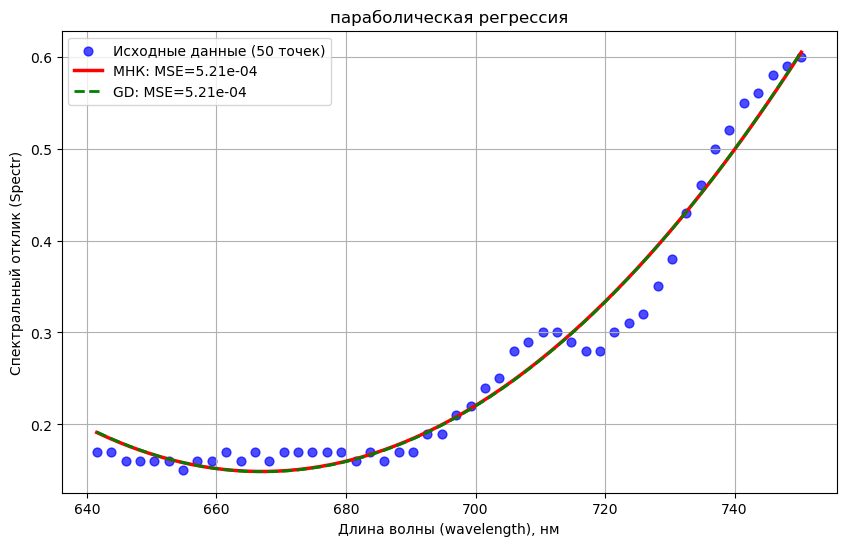

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

kukuruz_data = pd.read_csv("Corn_hyperspectrum.csv", sep=";", decimal=",")

sample = kukuruz_data.iloc[110:160].copy()
x = sample["wavelength"].values
Y = sample["Spectr"].values

p_analytic = np.polyfit(x, Y, deg=2)
a2_an, a1_an, a0_an = p_analytic

x_space = np.linspace(x.min(), x.max(), 200)
Y_pred_an_line = a0_an + a1_an * x_space + a2_an * (x_space**2)
Y_pred_an = a0_an + a1_an * x + a2_an * (x**2)

mse_an = ((Y - Y_pred_an) ** 2).mean()
r2_an = 1 - np.sum((Y - Y_pred_an) ** 2) / np.sum((Y - Y.mean()) ** 2)

print("Аналитическое")
print(f"a0 = {a0_an:.6f}")
print(f"a1 = {a1_an:.8f}")
print(f"a2 = {a2_an:.10f}")
print(f"MSE: {mse_an:.6e}, R^2: {r2_an:.4f}")

x_mean = x.mean()
x_std = x.std()
x_norm = (x - x_mean) / x_std


class SimpleQuadraticRegression:

    def __init__(self):
        self.a0 = 0.0
        self.a1 = 0.0
        self.a2 = 0.0

    def predict(self, x):
        return self.a0 + self.a1 * x + self.a2 * (x**2)

    def MSE(self, x, Y):
        return ((Y - self.predict(x)) ** 2).mean()

    def fit(self, x_in, Y_in, alpha=0.01, epsylon=1e-8, max_steps=20000):
        steps, errors = [], []
        n = len(Y_in)

        for step in range(1, max_steps + 1):
            pred = self.predict(x_in)
            diff = Y_in - pred

            dT_a0 = -2 * np.sum(diff) / n
            dT_a1 = -2 * np.sum(diff * x_in) / n
            dT_a2 = -2 * np.sum(diff * (x_in**2)) / n

            self.a0 -= alpha * dT_a0
            self.a1 -= alpha * dT_a1
            self.a2 -= alpha * dT_a2

            new_error = self.MSE(x_in, Y_in)
            steps.append(step)
            errors.append(new_error)

            if step > 1 and abs(errors[-2] - new_error) < epsylon:
                break

        return steps, errors


regr_gd = SimpleQuadraticRegression()
steps, errors = regr_gd.fit(x_norm, Y, alpha=0.05, max_steps=30000)

w0 = regr_gd.a0
w1 = regr_gd.a1
w2 = regr_gd.a2

a2_gd = w2 / (x_std**2)
a1_gd = (w1 / x_std) - (2 * w2 * x_mean / (x_std**2))
a0_gd = w0 - (w1 * x_mean / x_std) + (w2 * (x_mean**2) / (x_std**2))

Y_pred_gd = a0_gd + a1_gd * x + a2_gd * (x**2)
Y_pred_gd_line = a0_gd + a1_gd * x_space + a2_gd * (x_space**2)
mse_gd = ((Y - Y_pred_gd) ** 2).mean()

print("\nГрадиентный спуск")

print(f"a0 = {a0_gd:.6f}")
print(f"a1 = {a1_gd:.8f}")
print(f"a2 = {a2_gd:.10f}")
print(f"MSE: {mse_gd:.6e}")

plt.figure(figsize=(10, 6))
plt.scatter(x, Y, color="blue", s=40, label="Исходные данные (50 точек)", alpha=0.7)
plt.plot(
    x_space,
    Y_pred_an_line,
    color="red",
    linewidth=2.5,
    label=f"МНК: MSE={mse_an:.2e}",
)
plt.plot(
    x_space,
    Y_pred_gd_line,
    color="green",
    linestyle="--",
    linewidth=2,
    label=f"GD: MSE={mse_gd:.2e}",
)
plt.title("параболическая регрессия")
plt.xlabel("Длина волны (wavelength), нм")
plt.ylabel("Спектральный отклик (Spectr)")
plt.legend()
plt.grid(True)
plt.show()